# Loading, quality, plotting and animation

**Analytical question:** Inspect and visualize tracking data.

**Stages in this notebook:** Download and load; reshape; inspect quality; plot; animate.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Inspect the loaded representation

Start with the wide kloppy columns and the reshaped player rows. Check the keys and visibility before drawing anything.

In [4]:
display(wide[['period_id','frame_id','timestamp','ball_x','ball_y']].head())
display(tracking.groupby('team_id').agg(rows=('player_id','size'),detected_fraction=('is_detected','mean')))

,period_id,frame_id,timestamp,ball_x,ball_y
0,1,40,0 days 00:00:03,0.64,0.19
1,1,41,0 days 00:00:03.100000,1.10,0.18
2,1,42,0 days 00:00:03.200000,1.70,0.17
3,1,43,0 days 00:00:03.300000,2.36,0.16
4,1,44,0 days 00:00:03.400000,3.04,0.17


,rows,detected_fraction
team_id,,
871,67683,0.586573
1802,67683,0.581106


## 5. Extract one player

Select its x/y columns explicitly, preserving frame and period keys.

In [5]:
def extract_player_table(wide,player_id):
    columns=['period_id','frame_id','timestamp',f'{player_id}_x',f'{player_id}_y']
    return wide[columns].rename(columns={f'{player_id}_x':'x',f'{player_id}_y':'y'})
player=snapshot.player_id.iloc[0]
player_table=extract_player_table(wide,player)
display(player_table.head(8))

,period_id,frame_id,timestamp,x,y
0,1,40,0 days 00:00:03,-22.46,-10.06
1,1,41,0 days 00:00:03.100000,-22.46,-10.06
2,1,42,0 days 00:00:03.200000,-22.47,-10.05
3,1,43,0 days 00:00:03.300000,-22.48,-10.05
4,1,44,0 days 00:00:03.400000,-22.49,-10.04
5,1,45,0 days 00:00:03.500000,-22.51,-10.03
6,1,46,0 days 00:00:03.600000,-22.53,-10.01
7,1,47,0 days 00:00:03.700000,-22.56,-10.00


## 6. Inspect coordinate continuity

Compute frame-to-frame displacements only when observations are consecutive. These are intermediate inputs to later movement calculations.

,period_id,frame_id,timestamp,x,y,dx,dy,contiguous
0,1,40,0 days 00:00:03,-22.46,-10.06,NaN,NaN,False
1,1,41,0 days 00:00:03.100000,-22.46,-10.06,0.00,0.00,True
2,1,42,0 days 00:00:03.200000,-22.47,-10.05,-0.01,0.01,True
3,1,43,0 days 00:00:03.300000,-22.48,-10.05,-0.01,0.00,True
4,1,44,0 days 00:00:03.400000,-22.49,-10.04,-0.01,0.01,True
5,1,45,0 days 00:00:03.500000,-22.51,-10.03,-0.02,0.01,True
6,1,46,0 days 00:00:03.600000,-22.53,-10.01,-0.02,0.02,True
7,1,47,0 days 00:00:03.700000,-22.56,-10.00,-0.03,0.01,True
8,1,48,0 days 00:00:03.800000,-22.59,-9.97,-0.03,0.03,True
9,1,49,0 days 00:00:03.900000,-22.63,-9.94,-0.04,0.03,True


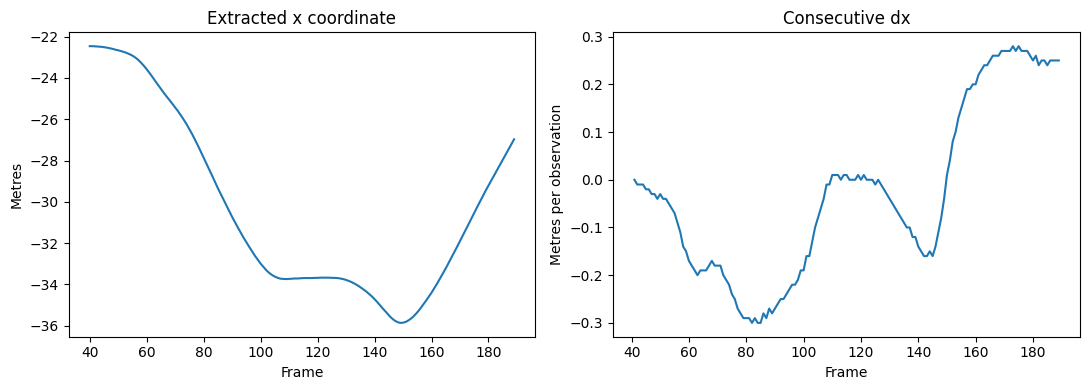

In [6]:
def coordinate_differences(table):
    result=table.copy();result['dx']=result.x.diff();result['dy']=result.y.diff()
    result['contiguous']=result.period_id.eq(result.period_id.shift())&result.frame_id.diff().eq(1)
    result.loc[~result.contiguous,['dx','dy']]=np.nan
    return result
player_table=coordinate_differences(player_table)
display(player_table.head(10))
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(player_table.frame_id.head(150),player_table.x.head(150));axs[0].set(title='Extracted x coordinate',xlabel='Frame',ylabel='Metres')
axs[1].plot(player_table.frame_id.head(150),player_table.dx.head(150));axs[1].set(title='Consecutive dx',xlabel='Frame',ylabel='Metres per observation')
plt.tight_layout();plt.show()

## 7. Build the pitch and add player layers

Draw the coordinate system first, then overlay a single real frame.

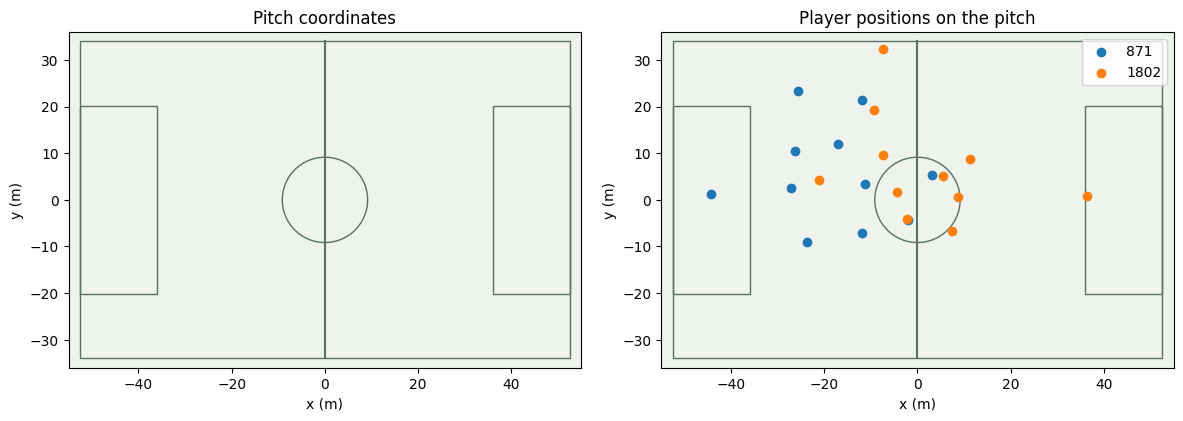

In [7]:
def plot_players(players,ax):
    for team,g in players.groupby('team_id'):ax.scatter(g.x,g.y,label=str(team))
    ax.legend();return ax
fig,axs=plt.subplots(1,2,figsize=(12,4));pitch(axs[0]);axs[0].set_title('Pitch coordinates')
pitch(axs[1]);plot_players(snapshot,axs[1]);axs[1].set_title('Player positions on the pitch');plt.tight_layout();plt.show()

## 8. Select a continuous animation clip

Choose consecutive complete frames and inspect the first/last snapshots before creating playback.

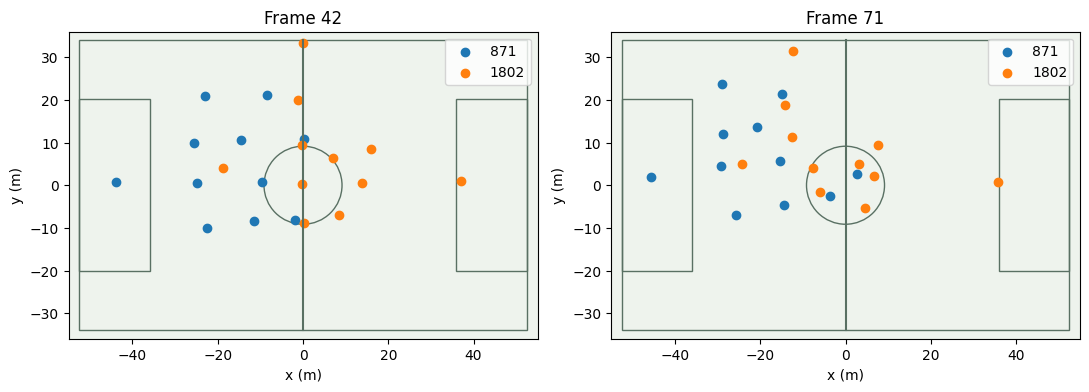

In [8]:
coverage=observed.groupby('frame_id').size();available=set(coverage[coverage.eq(22)].index)
start=next(f for f in sorted(available) if all(f+j in available for j in range(30)))
clip=observed[observed.frame_id.between(start,start+29)]
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,frame in zip(axs,[start,start+29]):pitch(ax);plot_players(clip[clip.frame_id.eq(frame)],ax);ax.set_title(f'Frame {frame}')
plt.tight_layout();plt.show()

## 9. Final output: animate the inspected clip

Only now connect the prepared frames to an animation update function.

In [9]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
fig,ax=plt.subplots(figsize=(8,5));pitch(ax);scat=ax.scatter([],[],s=60)
def update(i):
    g=clip[clip.frame_id.eq(start+i)]
    scat.set_offsets(g[['x','y']].to_numpy());scat.set_color(np.where(g.team_id.eq(1802),'#e87524','#7761be'))
    ax.set_title(f'Frame {start+i}');return (scat,)
animation=FuncAnimation(fig,update,frames=30,interval=100,blit=False)
plt.close(fig);display(HTML(animation.to_jshtml()))

## Interpretation and limitations

Coordinates may be extrapolated rather than directly observed. An animation helps inspect identity and movement, but does not validate tracking accuracy. [SkillCorner](https://github.com/SkillCorner/opendata).